# NATRE replication from the refreshed local archive

This review reads the November 13 Python processing run from the frozen November 9, 2026 local Argo archive. The validation report below determines whether the full 6,261-profile comparison and the deterministic regional summary pass bitwise.

The aggregate `<WMO>_prof.nc` files reproduce all 10,483 historical raw P/T/S arrays. Standard CF time decoding also reproduces their timestamps. The Python pipeline uses those local files, primary sampling, and Argopy research QC. Historical arrays serve only as comparison targets.

**Acceptance:** all historical profile arrays, coordinates, population, order, dtypes, and bytes must match; all historical deterministic regional arrays must match. Historical bootstrap estimates are explicitly exempt. Additional diagnostics and provenance do not imply identical NetCDF-container bytes or identical schemas.

**Run All is read-only:** it reads saved results, checks arrays, and renders the original plotting code. It does not load raw Argo profiles, recompute mixing, rerun bootstraps, download data, or process global Argo. Each original saved figure is followed by its local-source rendering.

Use the **Argo_Feb_25** environment.


In [1]:
from pathlib import Path
import os
os.environ.setdefault("MPLCONFIGDIR", "/tmp/argo-mixing-runtime/matplotlib")
os.environ.setdefault("NUMBA_CACHE_DIR", "/tmp/argo-mixing-runtime/numba")
os.environ.setdefault("XDG_CACHE_HOME", "/tmp/argo-mixing-runtime/cache")
os.environ.setdefault("PIP_CACHE_DIR", "/tmp/argo-mixing-runtime/pip")
import base64
import hashlib
import json
import sys
import warnings
warnings.filterwarnings("ignore", message="Engine 'erddapy' loading failed:.*")
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image, Code

candidates = [Path.cwd(), Path.cwd() / "notebooks/espe_code",
              Path("/home/amf2288/argo-intern/notebooks/espe_code")]
NOTEBOOK_DIR = next(p for p in candidates if (p / "natre_figure_review.py").is_file())
if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))
from natre_figure_review import (compare_datasets, figure_requirements, render_summary_figure,
                                render_profile_figure)

SOURCE_NOTEBOOK = NOTEBOOK_DIR / "plots_mixing_NATRE_gamman_analysis.ipynb"
EXPECTED_SOURCE_SHA256 = "47b41ac83a360ba4a30b79acf5fcab9c725c5cccbdaad7f7bc9fabb46f7edfbb"
assert hashlib.sha256(SOURCE_NOTEBOOK.read_bytes()).hexdigest() == EXPECTED_SOURCE_SHA256, (
    "The original notebook has changed since this review was prepared. Review its changes "
    "before updating the recorded hash; saved images and current code may differ."
)
original_notebook = json.loads(SOURCE_NOTEBOOK.read_text())
DATA_ROOT = Path("/swot/SUM05/amf2288")
SNAPSHOT = DATA_ROOT / "argo_snapshots/gdac_20261109_138320"
REFRESH = DATA_ROOT / "argo_mixing/natre_replication_20261113"
NEW_RUN = REFRESH / "validation"
OLD_RUN = DATA_ROOT / "argo_mixing/natre_validation_20261110"
REFERENCE_SUMMARY = DATA_ROOT / "espe_code/NATRE_Argo_mixing_gamman.nc"

# Explicit refreshed local result. Validation and provenance are checked below.
LOCAL_STAGE = NEW_RUN / "local"
SHOW_PLOTTING_CODE = False
REDRAW_SAVED_REFERENCE_SUMMARIES = False
print("Read-only review. Refreshed local scientific result: not selected." if LOCAL_STAGE is None
      else f"Candidate stage: {LOCAL_STAGE}")


Candidate stage: /swot/SUM05/amf2288/argo_mixing/natre_replication_20261113/validation/local


## Existing evidence

These are saved results from earlier work, not analyses launched by this notebook. Physical-profile agreement is distinct from exact input values, final scientific arrays, and rendered pixels.


In [2]:
snapshot_manifest = json.loads((SNAPSHOT / "snapshot_manifest.json").read_text())
input_audit = json.loads((REFRESH / "aggregate_input_audit.json").read_text())
validation = json.loads((NEW_RUN / "validation.json").read_text())
s = input_audit["summary"]
assert validation["comparison_policy"] == "bitwise_reference_arrays_with_full_population_and_order"
evidence = pd.DataFrame([
    ("Frozen core snapshot", snapshot_manifest["status"], f'{snapshot_manifest["index_records"]:,} indexed profiles verified present'),
    ("Local aggregate raw inputs", "PASS" if s["all_raw_inputs_exact_with_cf_time"] == s["saved_in_range_raw_profiles"] else "FAIL",
     f'{s["all_raw_inputs_exact_with_cf_time"]:,}/{s["saved_in_range_raw_profiles"]:,} raw profiles; P/T/S bytes, coordinates, and CF time'),
    ("NATRE physical population", "PASS" if s["identity_population_matches"] else "FAIL",
     f'{s["primary_diagnostic_accepted_profiles"]:,} accepted profiles; no missing or extra identities'),
    ("Refreshed local profile science", "PASS" if validation.get("local_profiles", {}).get("passed") else "PENDING / FAIL",
     "All 34 historical variables and three coordinates; full population and order"),
    ("Local deterministic regional summary", "PASS" if validation.get("historical_summary", {}).get("deterministic_passed") else "PENDING / FAIL",
     "All 17 historical deterministic variables and two coordinates"),
    ("Historical bootstrap realization", "EXEMPT", "Differences are reported; they do not relax deterministic checks"),
    ("Global processing", "NOT STARTED", "NATRE review precedes global expansion"),
], columns=["Check", "Status", "Scope"])
display(evidence)
assert validation["passed"], "The new local run has not passed the full bitwise replication gate."


,Check,Status,Scope
0,Frozen core snapshot,complete,"3,434,826 indexed profiles verified present"
1,Local aggregate raw inputs,PASS,"10,483/10,483 raw profiles; P/T/S bytes, coord..."
2,NATRE physical population,PASS,"6,261 accepted profiles; no missing or extra i..."
3,Refreshed local profile science,PASS,All 34 historical variables and three coordina...
4,Local deterministic regional summary,PASS,All 17 historical deterministic variables and ...
5,Historical bootstrap realization,EXEMPT,Differences are reported; they do not relax de...
6,Global processing,NOT STARTED,NATRE review precedes global expansion


## Local-source provenance and bitwise comparison

The candidate must use the refreshed local aggregate files, NATRE bounds and dates, and all 6,261 profiles. The saved profile validation checks the full population and order. The summary comparison below independently reads the saved arrays and checks dimensions, dtypes, and bytes without alignment or numerical tolerance.

Deterministic fields determine acceptance. Bootstrap-derived fields and additional diagnostics are also displayed, with their different comparison scope explicit. Identical scientific arrays do not establish identical figure pixels; historical bootstrap realizations are not required.


In [3]:
with xr.open_dataset(REFERENCE_SUMMARY, engine="netcdf4") as opened:
    reference = opened.load()
candidate = None
comparison = None
candidate_manifest = None
if LOCAL_STAGE is None:
    display(Markdown("**PENDING:** no refreshed local summary has been selected. No equality claim is made."))
else:
    local_stage = Path(LOCAL_STAGE).expanduser().resolve()
    candidate_manifest = json.loads((local_stage / "manifest.json").read_text())
    cfg = candidate_manifest["config"]
    assert candidate_manifest["status"] == "complete", "Candidate profile stage is incomplete."
    assert cfg["source"] == "local", "Candidate must come from local GDAC inputs."
    assert cfg["local_layout"] == "aggregate"
    assert cfg["code_sha256"] == validation["script_sha256"]
    assert candidate_manifest["summary_code_sha256"] == validation["script_sha256"]
    assert Path(cfg["gdac"]).resolve() == SNAPSHOT.resolve(), "Candidate uses a different archive."
    assert cfg["bounds"] == [-38, -20, 19, 32], "Candidate region differs from NATRE."
    assert cfg["start"] == "2014-01-01" and cfg["end"] == "2024-01-01", "Candidate dates differ."
    assert candidate_manifest["accepted_profiles"] == 6261, "Candidate population count differs."
    with xr.open_dataset(local_stage / "summaries/region.nc", engine="netcdf4") as opened:
        candidate = opened.load()
    assert candidate.attrs.get("input_profile_count", candidate.attrs.get("input_profiles")) == 6261
    display(Markdown("**Candidate provenance:** " + str(local_stage)))
    display(pd.DataFrame([{"archive": cfg["gdac"], "profiles": candidate_manifest["accepted_profiles"],
                           "summary_seed": candidate.attrs.get("bootstrap_seed"),
                           "profile_code_sha256": cfg.get("code_sha256"),
                           "summary_code_sha256": candidate_manifest.get("summary_code_sha256")}]))
    comparison = compare_datasets(reference, candidate)
    deterministic_names = validation["historical_summary"]["deterministic_variables"]
    deterministic_comparison = compare_datasets(reference[deterministic_names], candidate[deterministic_names])
    assert deterministic_comparison["summary"]["all_reference_variables_bitwise"]
    display(Markdown("**Deterministic historical arrays: bitwise PASS.**"))
    display(deterministic_comparison["summary"])
    display(Markdown("**Complete historical summary comparison, including exempt bootstrap-derived fields:**"))
    display(comparison["summary"])
    display(pd.DataFrame(comparison["variables"]))


**Candidate provenance:** /swot/SUM05/amf2288/argo_mixing/natre_replication_20261113/validation/local

,archive,profiles,summary_seed,profile_code_sha256,summary_code_sha256
0,/swot/SUM05/amf2288/argo_snapshots/gdac_202611...,6261,20261110,abc425c7f264d7eac5982bac99714b42dc27edeede1865...,abc425c7f264d7eac5982bac99714b42dc27edeede1865...


**Deterministic historical arrays: bitwise PASS.**

{'dimensions_equal': True,
 'reference_dimensions_equal': True,
 'reference_variables': 19,
 'candidate_variables': 19,
 'missing_candidate_variables': 0,
 'extra_candidate_variables': 0,
 'reference_variables_exact': 19,
 'all_reference_variables_exact': True,
 'reference_variables_bitwise': 19,
 'all_reference_variables_bitwise': True,
 'dataset_arrays_bitwise': True,
 'coordinates_bitwise': True,
 'dataset_values_exact': True,
 'coordinates_exact': True,
 'attributes_compared': False,
 'alignment_or_tolerances_used': False}

**Complete historical summary comparison, including exempt bootstrap-derived fields:**

{'dimensions_equal': False,
 'reference_dimensions_equal': True,
 'reference_variables': 51,
 'candidate_variables': 231,
 'missing_candidate_variables': 0,
 'extra_candidate_variables': 180,
 'reference_variables_exact': 19,
 'all_reference_variables_exact': False,
 'reference_variables_bitwise': 19,
 'all_reference_variables_bitwise': False,
 'dataset_arrays_bitwise': False,
 'coordinates_bitwise': True,
 'dataset_values_exact': False,
 'coordinates_exact': True,
 'attributes_compared': False,
 'alignment_or_tolerances_used': False}

,variable,coordinate,reference_dims,candidate_dims,reference_shape,candidate_shape,reference_dtype,candidate_dtype,dtype_equal,status,values_exact,bitwise_equal,missing_mask_equal,different_values,max_abs_difference,nonfinite_mismatches,max_abs_difference_ns
0,CT,False,"[SG, TIME]","[SG, TIME]","[26, 40]","[26, 40]",float64,float64,True,equal,True,True,True,0.0,0.0,0.0,NaN
1,CT_contour,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,extra_candidate,False,False,NaN,NaN,NaN,NaN,NaN
2,CT_time_anomaly,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,extra_candidate,False,False,NaN,NaN,NaN,NaN,NaN
3,CT_time_mean,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,extra_candidate,False,False,NaN,NaN,NaN,NaN,NaN
4,CT_time_p05,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,extra_candidate,False,False,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
226,var_CT,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,extra_candidate,False,False,NaN,NaN,NaN,NaN,NaN
227,var_SA,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,extra_candidate,False,False,NaN,NaN,NaN,NaN,NaN
228,vgeos,False,NaN,NaN,NaN,NaN,NaN,NaN,NaN,extra_candidate,False,False,NaN,NaN,NaN,NaN,NaN
229,z,False,"[SG, TIME]","[SG, TIME]","[26, 40]","[26, 40]",float64,float64,True,equal,True,True,True,0.0,0.0,0.0,NaN


## Figure-by-figure review

**Historical reference** always means the saved image embedded in the original notebook. These bytes are preserved exactly, but showing them is not independent reproduction. **Local candidate** always means saved output from the explicitly selected refreshed run.

The helper uses the original plotting code and the Python pipeline’s saved figure products. Cells 6, 10, and 23 substitute saved statistics for the original reductions; no bootstrap draws are generated. Cell 11 reads saved profile CT/SA arrays. Missing ingredients are reported explicitly. No reference values are substituted for missing local values. Optional reference-summary redraws are also labeled and are disabled by default.

The original notebook used an unsaved bootstrap random state. Its particular confidence bands cannot be independently regenerated bit-for-bit from raw data without those draws/state. Historical bootstrap differences are explicitly permitted for this replication. The underlying deterministic arrays remain subject to bitwise equality. Font and Matplotlib versions can also change pixels even when numerical plot inputs match.


In [4]:
FIGURES = [(6, 'Missing thermal dissipation by resolution bin'), (9, 'Dissipation and sampling-resolution sections'), (10, 'Mean stratification proxy and dissipation'), (11, 'Temperature–salinity and salinity–depth curves'), (17, 'Isopycnal slopes and geostrophic velocities'), (20, 'Regional mixing and hydrographic changes'), (21, 'Mean profiles and temporal percentile ranges'), (22, 'Mean profiles with standard-error bands'), (23, 'Mean profiles with pooled-bootstrap bands'), (24, 'Gradients and variance-production anomalies')]
SUMMARY_FIGURES = (6, 9, 10, 17, 20, 21, 22, 23, 24)
REFERENCE_REDRAW_CELLS = (20, 21, 22, 24)

def show_original_figure(cell_index):
    cell = original_notebook["cells"][cell_index]
    display(Markdown(f"**Historical reference — original cell index {cell_index}. Saved PNG; no recalculation.**"))
    images = [out["data"]["image/png"] for out in cell.get("outputs", [])
              if "image/png" in out.get("data", {})]
    if not images:
        raise ValueError(f"No saved image in original cell {cell_index}")
    for encoded in images:
        if isinstance(encoded, list):
            encoded = "".join(encoded)
        display(Image(data=base64.b64decode(encoded)))
    if SHOW_PLOTTING_CODE:
        display(Code("".join(cell["source"]), language="python"))

def show_local_figure(cell_index):
    if candidate is None:
        display(Markdown("**Local candidate: PENDING — refreshed scientific outputs have not been produced.**"))
        return
    if cell_index == 11:
        # This file contains only local-source arrays, already in reference order.
        profile_path = local_stage / "NATRE_profiles_replica.nc"
        replica_report = json.loads(profile_path.with_suffix(".json").read_text())
        assert replica_report["passed"] and replica_report["all_reference_arrays_bitwise"]
        assert replica_report["producing_script_sha256"] == validation["script_sha256"]
        with xr.open_dataset(profile_path, engine="netcdf4") as opened:
            profiles = opened[["CT", "SA"]]
            assert profiles.sizes["time"] == 6261
            display(Markdown("**Local candidate — validated local-source profile replica, original plotting code.**"))
            fig = render_profile_figure(profiles, source_notebook=SOURCE_NOTEBOOK)
            display(fig)
            plt.close(fig)
        return
    missing = figure_requirements(candidate, cell_index, source_notebook=SOURCE_NOTEBOOK)
    if missing:
        display(Markdown("**Local rendering unavailable; missing inputs:** `" + ", ".join(missing) + "`"))
        return
    display(Markdown("**Local candidate — saved Python-produced summary, original plotting code.**"))
    fig = render_summary_figure(candidate, cell_index, source_notebook=SOURCE_NOTEBOOK)
    display(fig)
    plt.close(fig)

def optionally_redraw_reference(cell_index):
    if REDRAW_SAVED_REFERENCE_SUMMARIES and cell_index in REFERENCE_REDRAW_CELLS:
        display(Markdown("**Optional redraw from saved historical summary — reference data, not local Argo reproduction.**"))
        fig = render_summary_figure(reference, cell_index, source_notebook=SOURCE_NOTEBOOK)
        display(fig)
        plt.close(fig)


### Missing thermal dissipation by resolution bin

Original notebook cell index `6` (zero-based).

**Historical reference — original cell index 6. Saved PNG; no recalculation.**

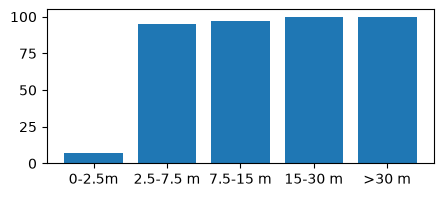

**Local candidate — saved Python-produced summary, original plotting code.**

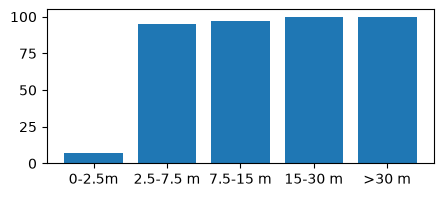

In [5]:
show_original_figure(6)
show_local_figure(6)
optionally_redraw_reference(6)


### Dissipation and sampling-resolution sections

Original notebook cell index `9` (zero-based).

**Historical reference — original cell index 9. Saved PNG; no recalculation.**

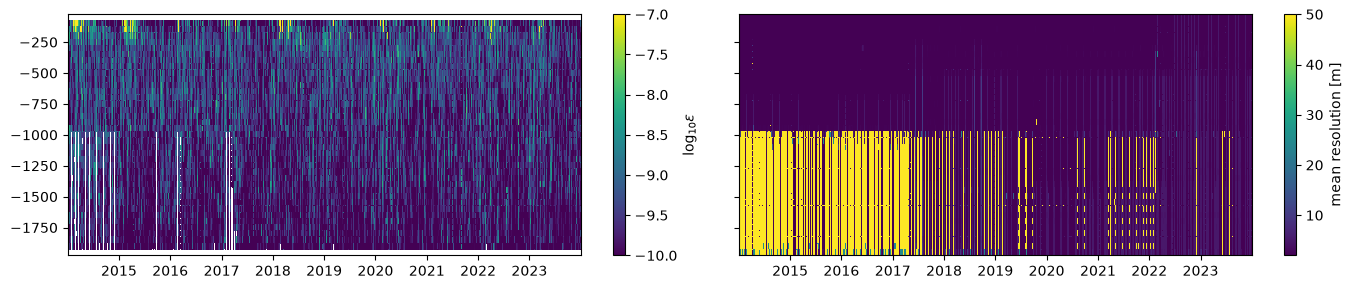

**Local candidate — saved Python-produced summary, original plotting code.**

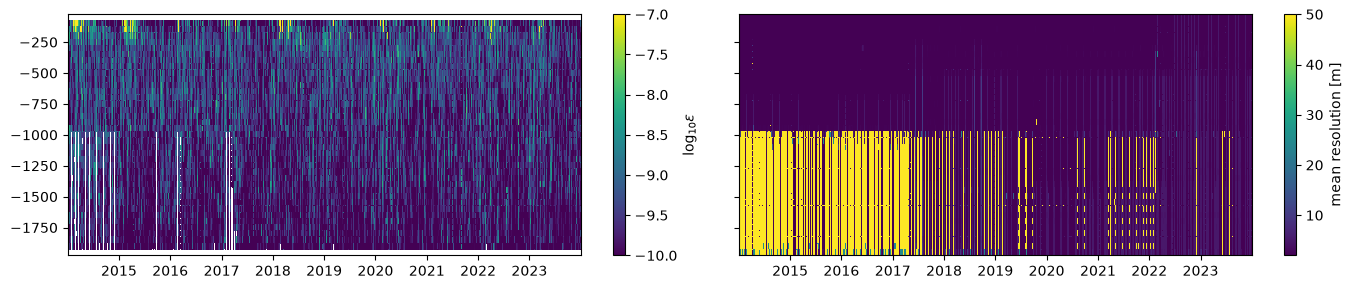

In [6]:
show_original_figure(9)
show_local_figure(9)
optionally_redraw_reference(9)


### Mean stratification proxy and dissipation

Original notebook cell index `10` (zero-based).

**Historical reference — original cell index 10. Saved PNG; no recalculation.**

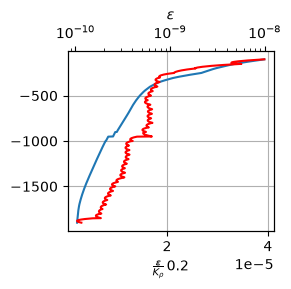

**Local candidate — saved Python-produced summary, original plotting code.**

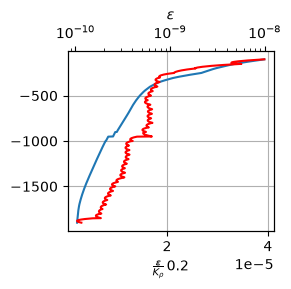

In [7]:
show_original_figure(10)
show_local_figure(10)
optionally_redraw_reference(10)


### Temperature–salinity and salinity–depth curves

Original notebook cell index `11` (zero-based).

**Historical reference — original cell index 11. Saved PNG; no recalculation.**

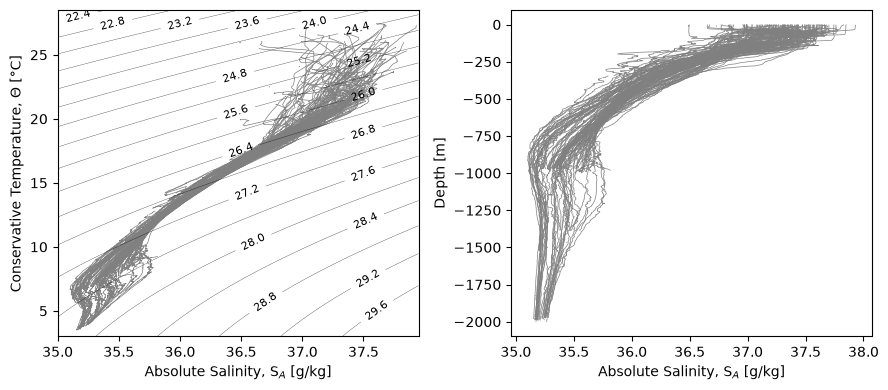

**Local candidate — validated local-source profile replica, original plotting code.**

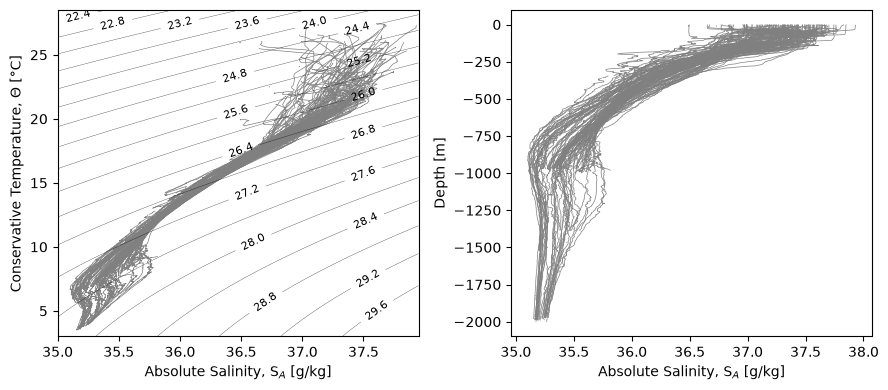

In [8]:
show_original_figure(11)
show_local_figure(11)
optionally_redraw_reference(11)


### Isopycnal slopes and geostrophic velocities

Original notebook cell index `17` (zero-based).

**Historical reference — original cell index 17. Saved PNG; no recalculation.**

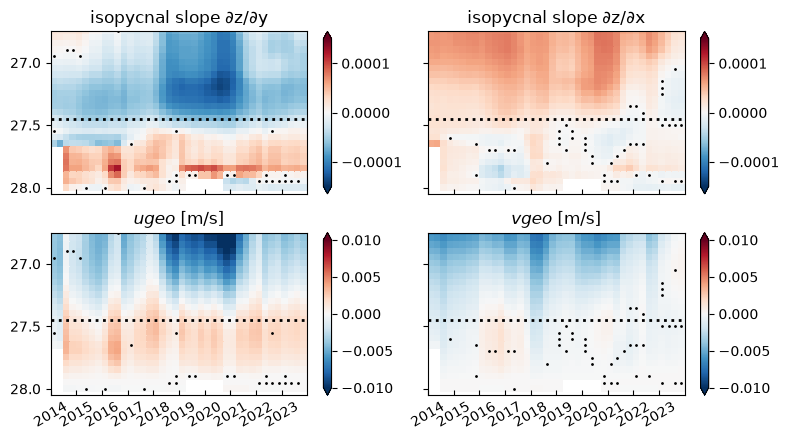

**Local candidate — saved Python-produced summary, original plotting code.**

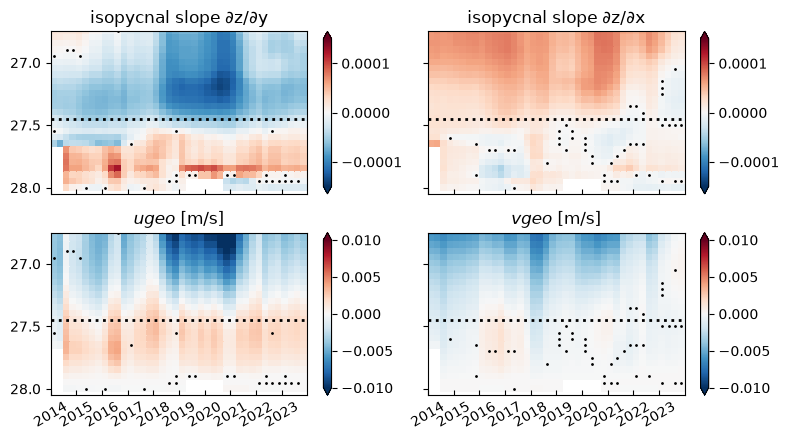

In [9]:
show_original_figure(17)
show_local_figure(17)
optionally_redraw_reference(17)


### Regional mixing and hydrographic changes

Original notebook cell index `20` (zero-based).

**Historical reference — original cell index 20. Saved PNG; no recalculation.**

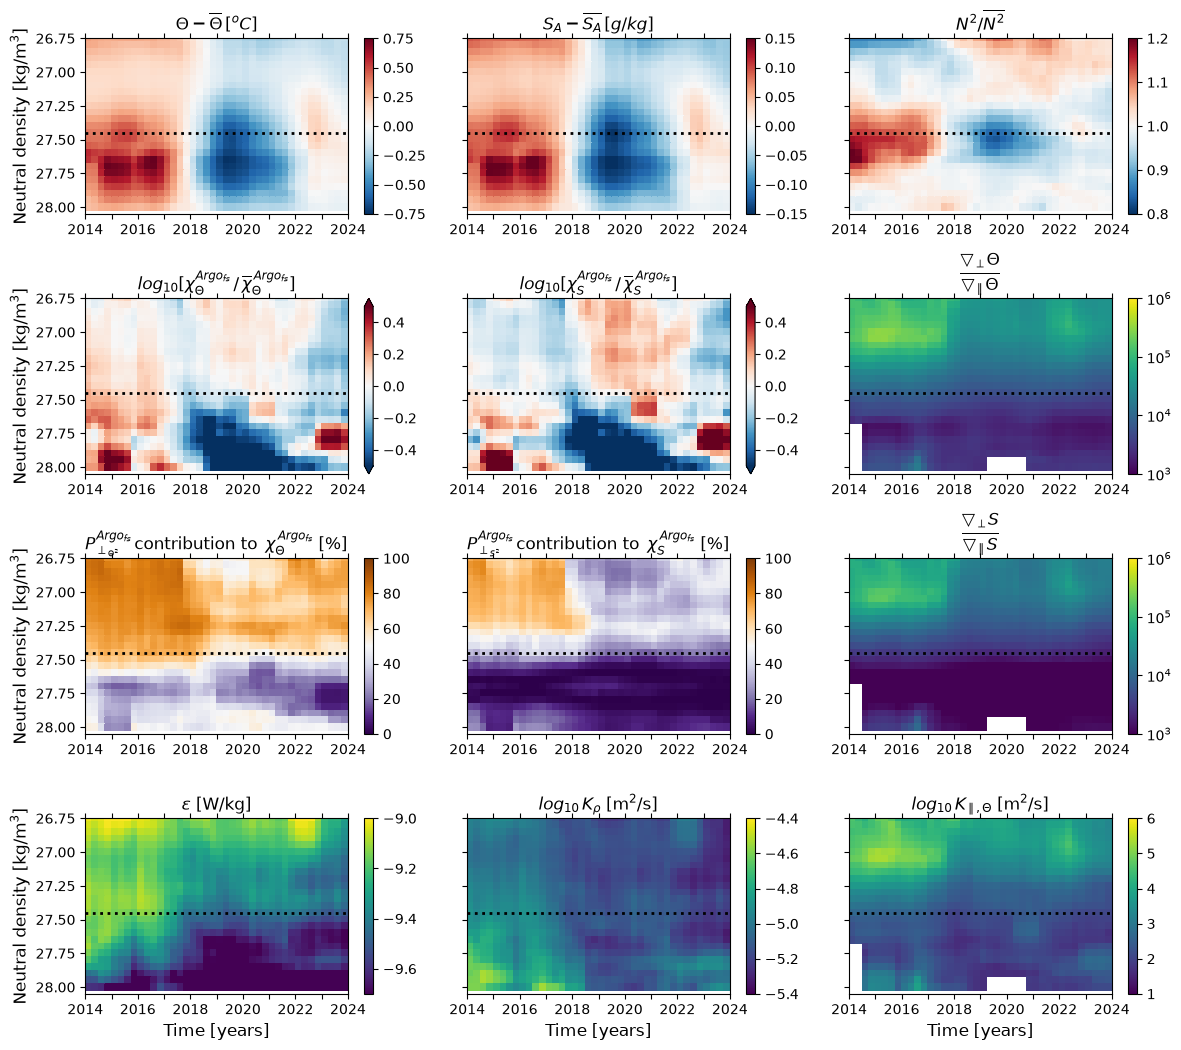

**Local candidate — saved Python-produced summary, original plotting code.**

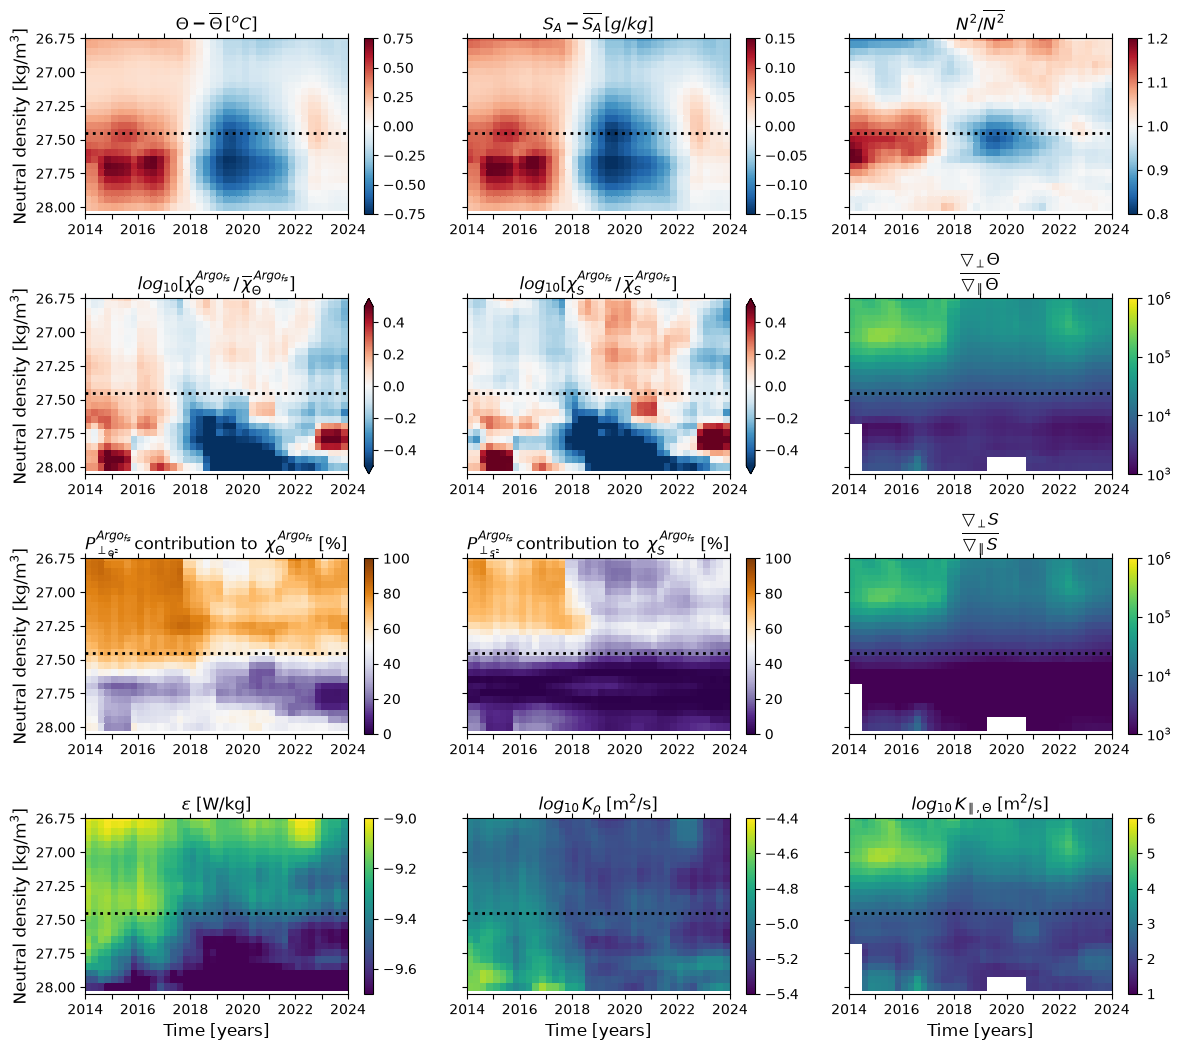

In [10]:
show_original_figure(20)
show_local_figure(20)
optionally_redraw_reference(20)


### Mean profiles and temporal percentile ranges

Original notebook cell index `21` (zero-based).

**Historical reference — original cell index 21. Saved PNG; no recalculation.**

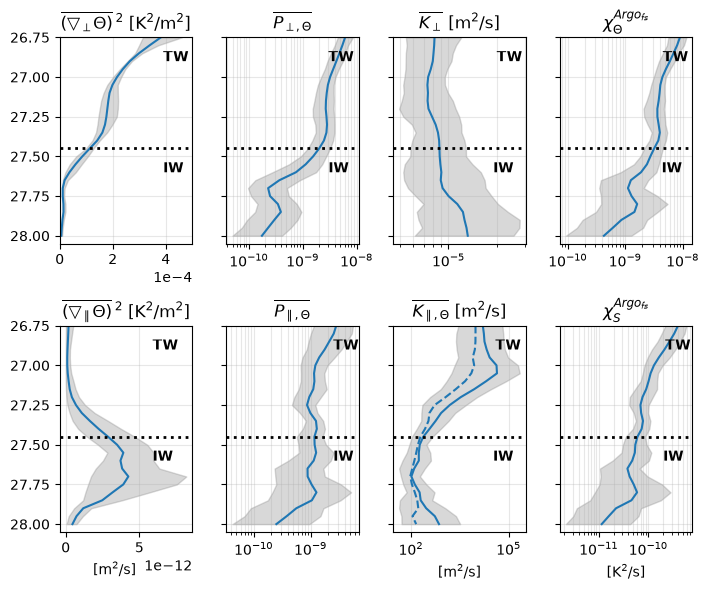

**Local candidate — saved Python-produced summary, original plotting code.**

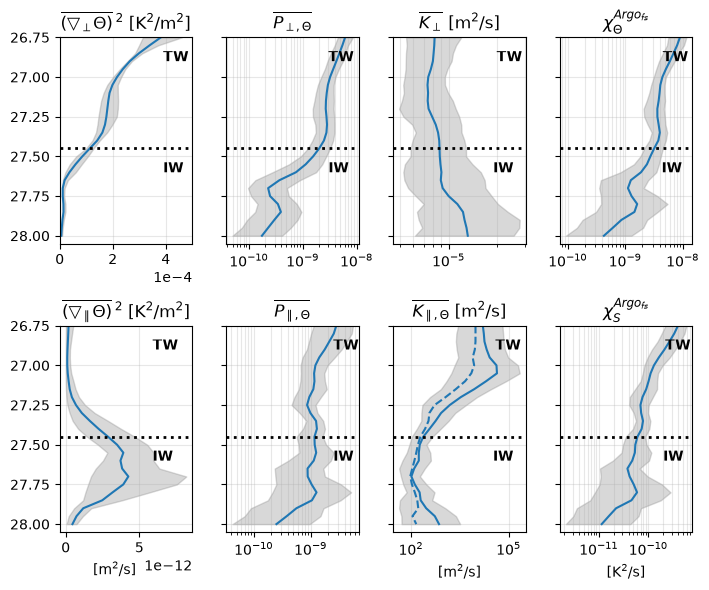

In [11]:
show_original_figure(21)
show_local_figure(21)
optionally_redraw_reference(21)


### Mean profiles with standard-error bands

Original notebook cell index `22` (zero-based).

**Historical reference — original cell index 22. Saved PNG; no recalculation.**

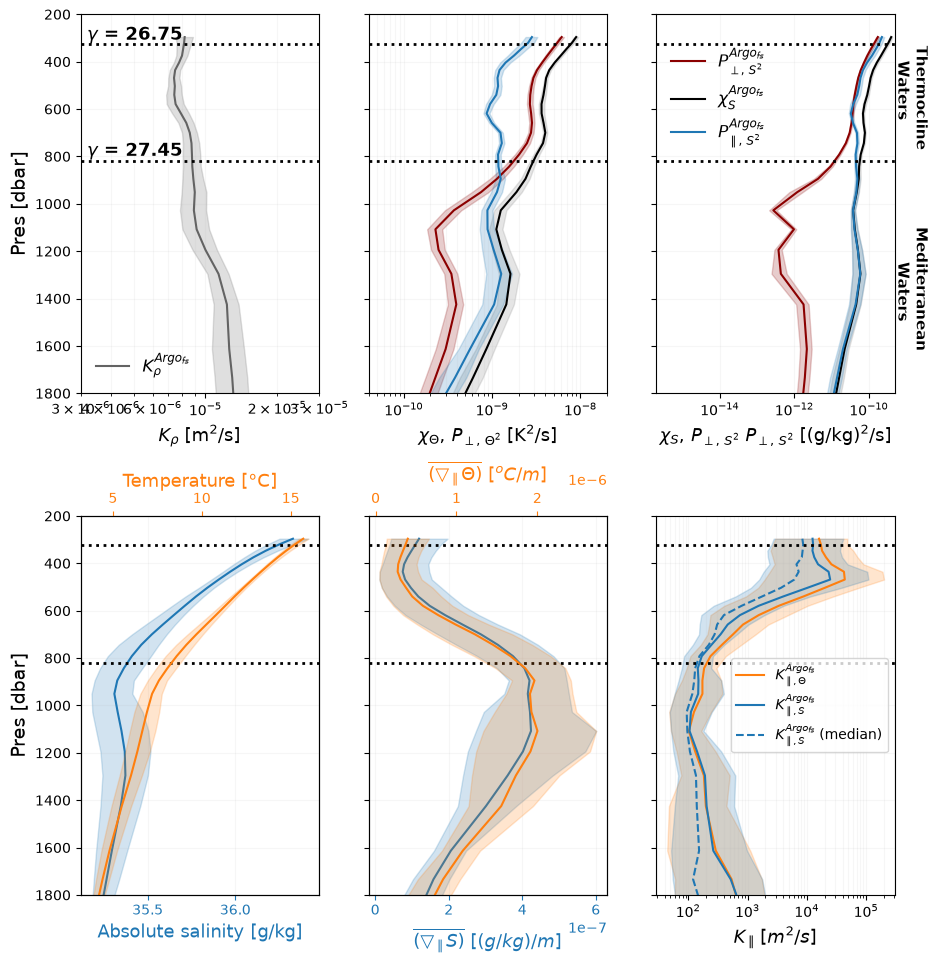

**Local candidate — saved Python-produced summary, original plotting code.**

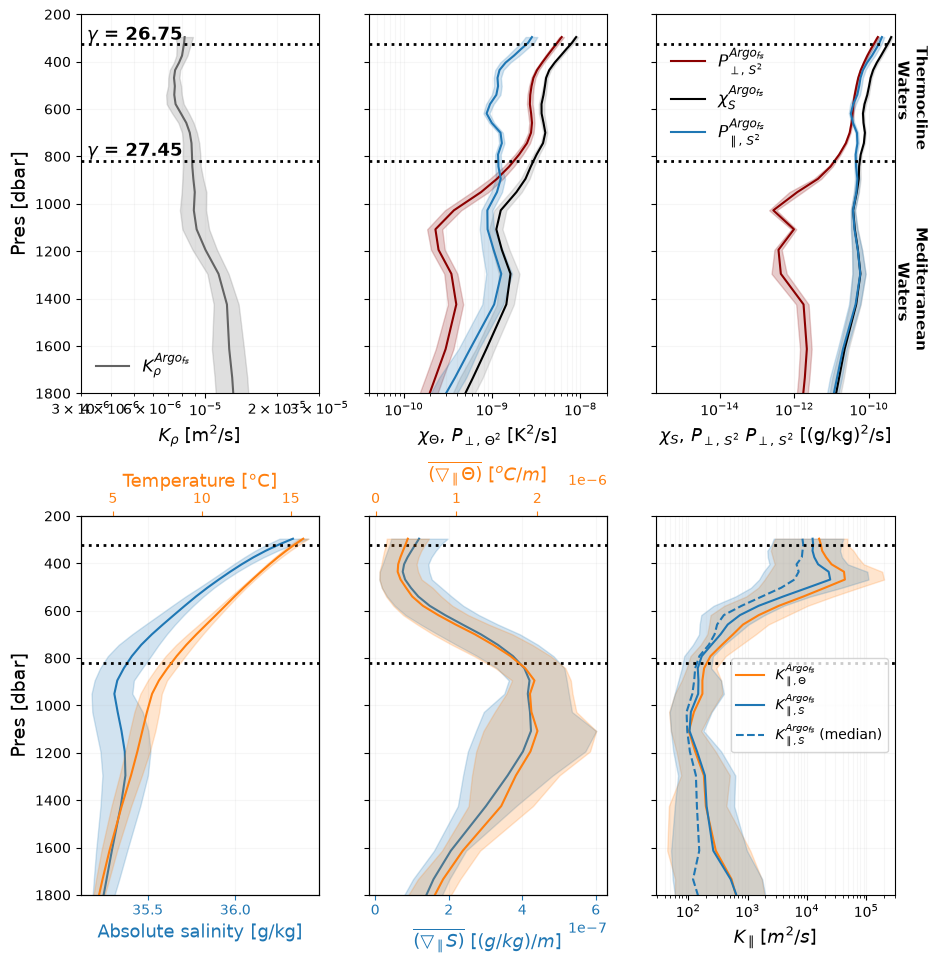

In [12]:
show_original_figure(22)
show_local_figure(22)
optionally_redraw_reference(22)


### Mean profiles with pooled-bootstrap bands

Original notebook cell index `23` (zero-based).

**Historical reference — original cell index 23. Saved PNG; no recalculation.**

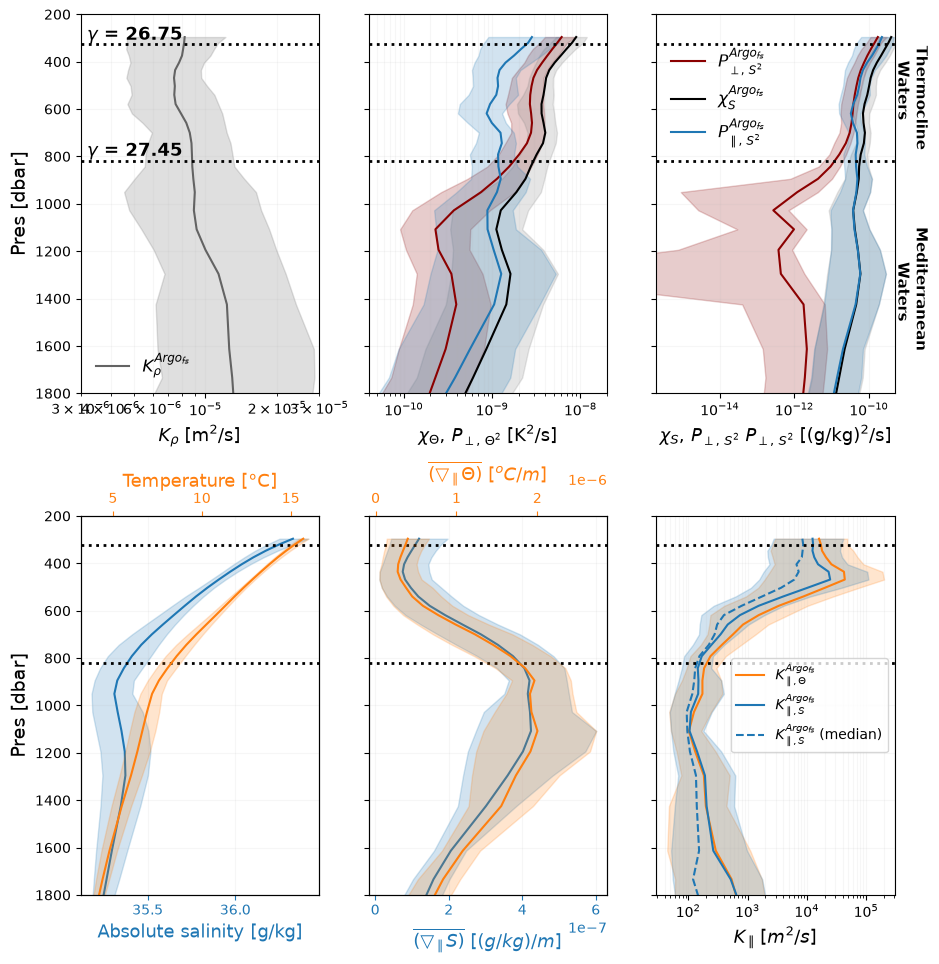

**Local candidate — saved Python-produced summary, original plotting code.**

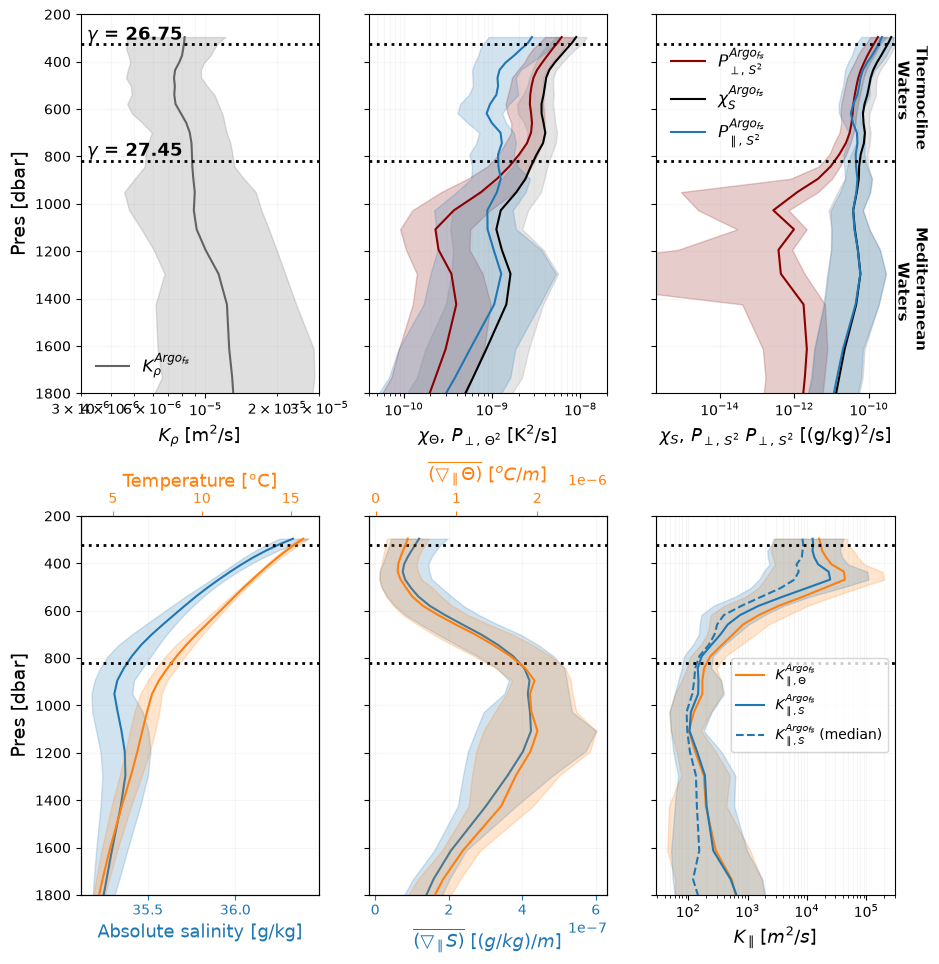

In [13]:
show_original_figure(23)
show_local_figure(23)
optionally_redraw_reference(23)


### Gradients and variance-production anomalies

Original notebook cell index `24` (zero-based).

**Historical reference — original cell index 24. Saved PNG; no recalculation.**

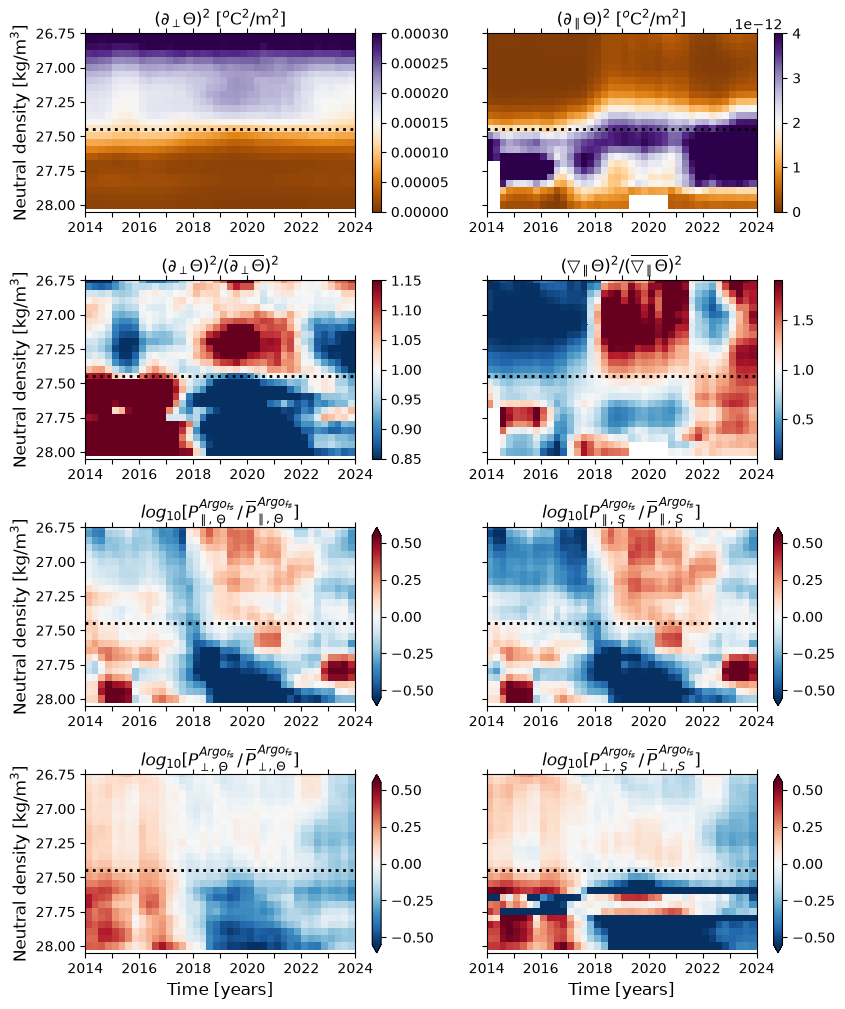

**Local candidate — saved Python-produced summary, original plotting code.**

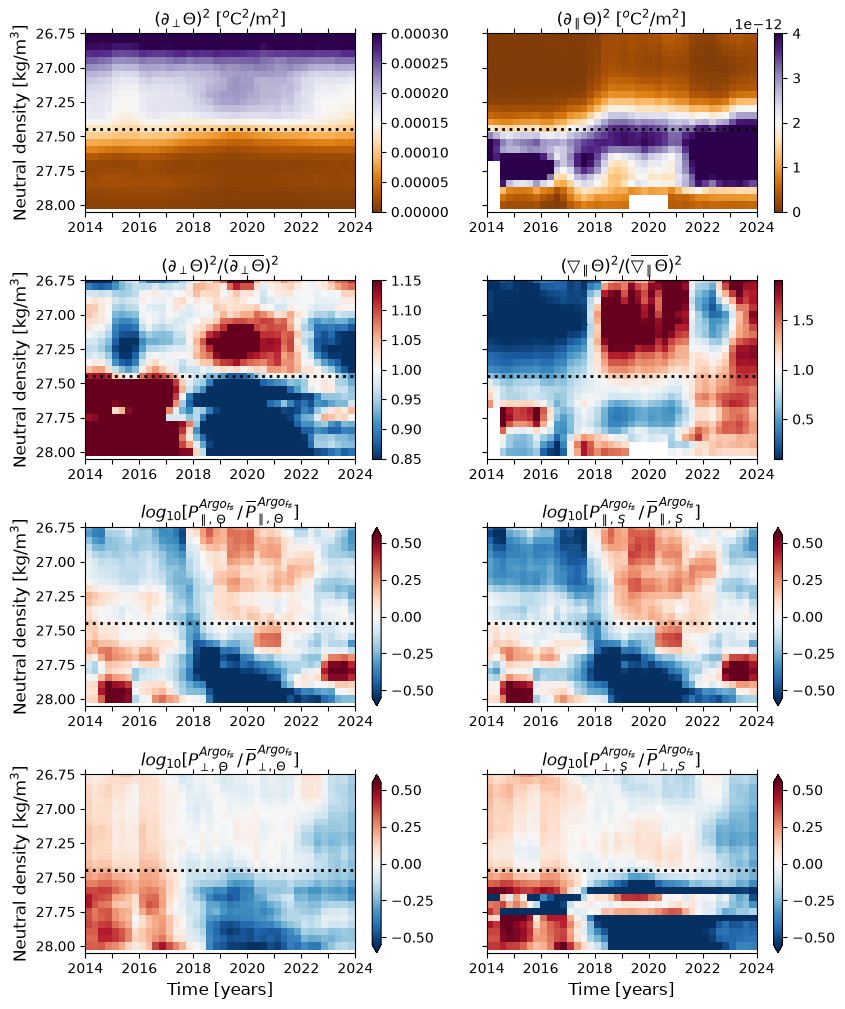

In [14]:
show_original_figure(24)
show_local_figure(24)
optionally_redraw_reference(24)


## Figure input inventory and next discussion

| Original cell indices | Required saved products | Current local redraw adapter |
| --- | --- | --- |
| 6 | Resolution-bin missing-χ percentages | Saved-statistic adapter |
| 9 | Cleaned ε section, mean resolution, profile times, Zfs | Implemented |
| 10 | Depth means of ε and ε/Kρ × 0.2 | Saved-statistic adapter |
| 11 | Full profile SA/CT/Z, every 50th profile; contour grid | Reads the saved local-source profile replica; aggregated SA/CT cannot substitute |
| 17 | Slopes, velocities, and significance masks | Implemented |
| 20, 21, 22, 24 | Saved regional summary arrays | Implemented using original plotting cells |
| 23 | Saved pooled-bootstrap statistics, including distinct 0.5%/2.5% lower bounds | Saved-statistic adapter; historical summary lacks original draws |

The evidence above comes from the refreshed aggregate archive and the full local-source run. The profile and deterministic-summary comparisons must pass before this notebook renders local figures. No historical data replace local figure inputs. Historical bootstrap estimates may differ.

NATRE validates this loading and processing path against known outputs. We will review the NATRE result and global aggregation settings before global expansion. This notebook contains no global processing action.
